<a href="https://colab.research.google.com/github/fluids/AI4GSD/blob/main/Demo_Colab/Demo3_Smartphone_Videos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI4GSD Demo
------------------------------------------
## Smartphone videos
------------------------------------------
#### Table of contents
#### 0. Installing requried packages
#### 1. Importing required packages
#### 2. Defining working directory
#### 3. Extracting or copying your videos/photos to desired folder
#### 4. Obtaining scales from AI, drone flight data, or manual measurements
#### 5. Obtaining segmentation of anthropogenic objects
#### 6. Obtaining grain size data
#### 7. Applying quality control
#### 8. Data visualization

##### *** Please contact Yunxiang Chen, yunxiang.chen@pnnl.gov for reporting errors

------------------------------------------
### 0. Installing requried packages

#### 0a. Install requried packages

In [16]:
%pip install -q ultralytics==8.3.186 natsort pyproj PyExifTool piexif imutils shapely psutil gdown

#### 0b. Connect Google drive to Colab runtime.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#### 0c. Create AI4GSD parent direcotry and download source codes if not found.

In [3]:
import sys, subprocess
from pathlib import Path
WorkDir = Path("/content/drive/MyDrive/AI4GSD")
sys.path.insert(0,str(WorkDir))
if not WorkDir.exists():subprocess.run(["git", "clone", "--progress","https://github.com/fluids/AI4GSD.git", str(WorkDir)],check=True)

### 1. Importing required packages

In [4]:
import AI4GSD

### 2. Defining working directory

In [5]:
AI4GSD.pcinfo()
foldername = '20250521_YC_WalkSmartphoneRoadTest'                          # Parent folder where you save photos/videos.
PhotoDir = str(WorkDir / 'Demo_Data' / foldername)                         # AI4GSD use string path.

Machine name: b15113a7d9c9
Operating system: Ubuntu 24.04.5 LTS
Architecture: x86_64
Processor: Intel(R) Xeon(R) CPU @ 2.20GHz
Reported CPU frequency: 2.20 GHz
PyTorch version: 2.14.1+cpu
CUDA available: False
CUDA GPU unavailable to PyTorch


### 3. Extracting or copying your videos/photos to desired folder

#### 3a. Downloading large video file seperately because git clone may ignore it.

In [6]:
videoname = "IMG_9683.MOV"
videosize = 1* 1024**2
video = Path(PhotoDir) / "videos" / videoname
video.parent.mkdir(parents=True, exist_ok=True)
url = f"https://media.githubusercontent.com/media/pnnl/AI4GSD/main/Demo_Data/20250521_YC_WalkSmartphoneRoadTest/videos/{videoname}"
if not video.exists() or video.stat().st_size < videosize:
  subprocess.run(["curl", "-fL", "--progress-bar", "-o", str(video), url], check=True)

#### 3b. Extracting frames from videos.



In [7]:
AI4GSD.getPhotos(PhotoDir,nframe=500, overwrite=False)                     # Use once.

Video photo output folder: /content/drive/MyDrive/AI4GSD/Demo_Data/20250521_YC_WalkSmartphoneRoadTest
Extracting IMG_9683.MOV every 500 frames.
IMG_9683.MOV: get frame 1 from 500/2171 in 0.00 s (23.03%), file existed, skipping...
IMG_9683.MOV: get frame 2 from 1000/2171 in 0.00 s (46.06%), file existed, skipping...
IMG_9683.MOV: get frame 3 from 1500/2171 in 0.00 s (69.09%), file existed, skipping...
IMG_9683.MOV: get frame 4 from 2000/2171 in 0.00 s (92.12%), file existed, skipping...

Computation done, elapsed time 2.04 seconds.




### 4. Obtaining scales from AI, drone flight data, or manual measurements

In [8]:
PP = AI4GSD.parameters()
PP.Directory = PhotoDir
PP.OverWriteAll = True                                                     # Overwrite everything if True.
PP.OverWriteScaleFile = False
PP.OverWriteScaleRows = True
PP.ScaleSource = 'AI'                                                      # Use AI option.
PP.ModelName = 'YOLO11m.1280.20250825'                                     # Which AI to use.
PP.ComputingSource = 'local'                                               # What computing resource to use.
PP.ConfidenceThresholdUser = 0.85                                          # Minimum confidence threshold.
PP.YOLOSave = False                                                        # Need to save AI prediction to folder.
scales =  AI4GSD.metadata(PP)

Generating scale file for: 20250521_YC_WalkSmartphoneRoadTest
Estimating photo resolution via local AI model: YOLO11m.1280.20250825
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Model layer: 113, model parmeter: 20.06M, submodule number: 409
IOU: 0.45, user confidence: 0.85
1/4: photo 1/4, IMG_9683_500.png, scale greencap, res 0.62 mm/px, status 200, (25.00%), 13.55 s
2/4: photo 2/4, IMG_9683_1000.png, scale greencap, res 0.59 mm/px, status 200, (50.00%), 4.40 s
3/4: photo 3/4, IMG_9683_1500.png, scale greencap, res 0.59 mm/px, status 200, (75.00%), 3.75 s
4/4: photo 4/4, IMG_9683_2000.png, scale greencap, res 0.65 mm/px, status 200, (100.00%), 3.94 s
Total time: 42.27 s, time per photo 10.57 s
-------------------------------

### 5. Obtaining segmentation of anthropogenic objects

In [9]:
PP = AI4GSD.parameters()
PP.Directory = PhotoDir
PP.FolderLevel = 'L1'
PP.ModelName = 'YOLO11m.640.20250906'
PP.ObjectName = 'anthro'
PP.OverWriteSegementation = True
PP.YOLOSave = False
PP.YOLOIOU = 0.45
PP.ComputingSource = 'local'
PP.ImageSizeType = 'default'
PP.SegmentationClassName =['people','road','steel']                        # What object class need to track.
AI4GSD.background(PP)

-----------------------------------------------------------------
Folder name: 20250521_YC_WalkSmartphoneRoadTest
output name: segments
Model name: YOLO11m.640.20250906 from local for anthro
Model layer: 125, model parmeter: 22.37M, submodule number: 445
IOU: 0.45, user confidence: 0.35
Number of photos: 4, number of exluded photos 0
20250521_YC_WalkSmartphoneRoadTest: 1/4: IMG_9683_500.png (25.00%)
20250521_YC_WalkSmartphoneRoadTest: 2/4: IMG_9683_1000.png (50.00%)
20250521_YC_WalkSmartphoneRoadTest: 3/4: IMG_9683_1500.png (75.00%)
20250521_YC_WalkSmartphoneRoadTest: 4/4: IMG_9683_2000.png (100.00%)
Total time: 22.00 s, time per photo 5.50 s
-----------------------------------------------------------------



### 6. Obtaining grain size data

AI4GSD: an AI and cloud powered tool for grain size quantification
AI models in use: YOLO11m.1280.20250322
Confidence thresholds in use: 0.35

-----------------------------------------------------------------
Folder name: 20250521_YC_WalkSmartphoneRoadTest
Output folder: 20250521_YC_WalkSmartphoneRoadTest_YOLO11m.1280.20250322_35
Model name: YOLO11m.1280.20250322 from local for rock detection
Model layer: 113, model parmeter: 20.05M, submodule number: 409
IOU: 0.45, YOLO confidence: 0.25, user confidence: 0.35
Number of photos: 4, number of exluded photos 0
1/4: IMG_9683_500.png, resolution 0.62 mm/px (25.00%), 0.00 s
Detected 601 rocks, diagonal and count based D10, D50, D60, and D84 are: 2.58, 4.14, 4.48, and 5.61 cm
Detected 601 rocks, diagonal and area  based D10, D50, D60, and D84 are: 3.34, 5.01, 5.35, and 6.41 cm


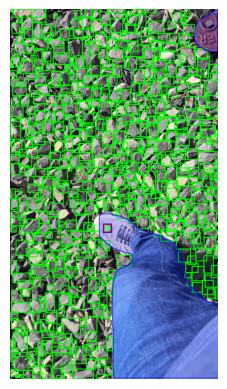

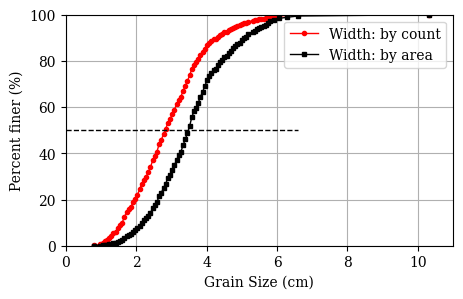

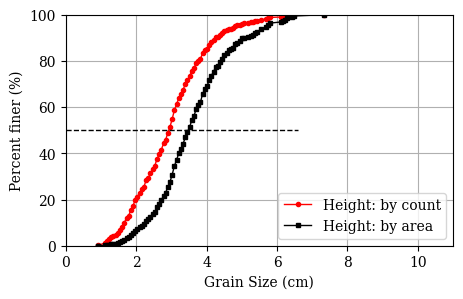

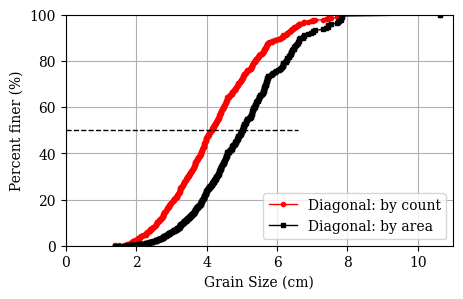

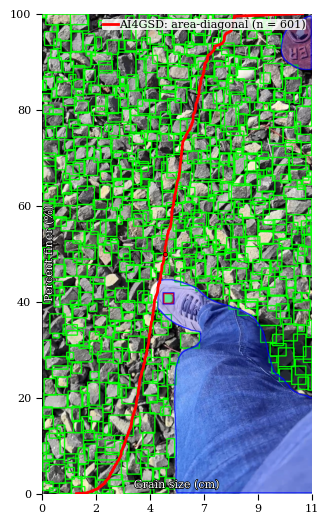

2/4: IMG_9683_1000.png, resolution 0.59 mm/px (50.00%), 11.69 s
Detected 639 rocks, diagonal and count based D10, D50, D60, and D84 are: 2.12, 3.53, 3.82, and 4.75 cm
Detected 639 rocks, diagonal and area  based D10, D50, D60, and D84 are: 2.77, 4.32, 4.58, and 5.50 cm


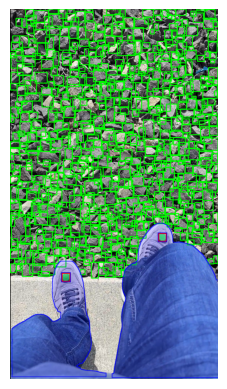

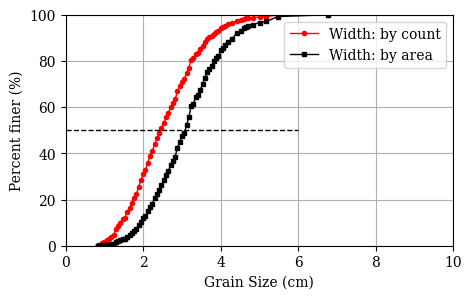

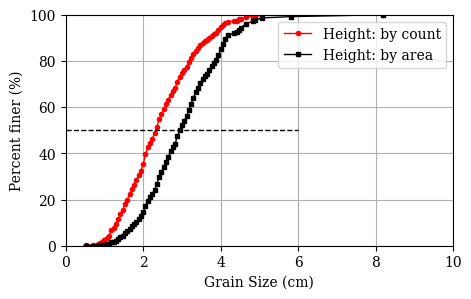

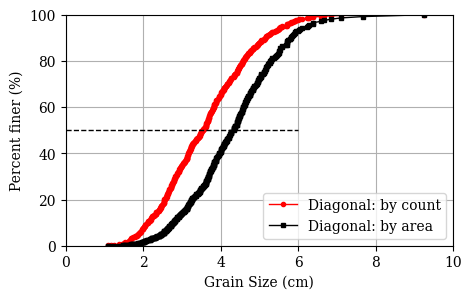

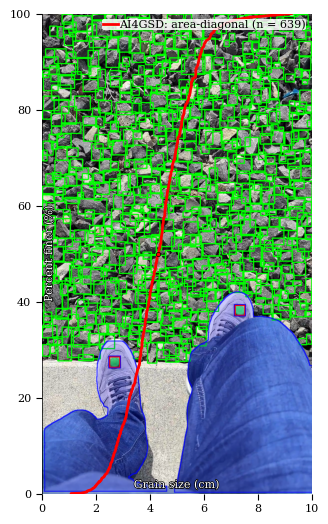

3/4: IMG_9683_1500.png, resolution 0.59 mm/px (75.00%), 11.35 s
Detected 628 rocks, diagonal and count based D10, D50, D60, and D84 are: 2.21, 3.64, 3.97, and 4.83 cm
Detected 628 rocks, diagonal and area  based D10, D50, D60, and D84 are: 2.97, 4.39, 4.65, and 5.51 cm


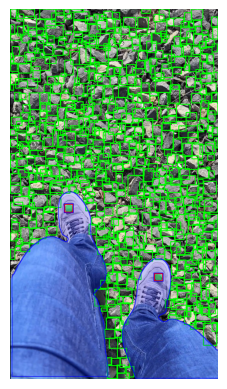

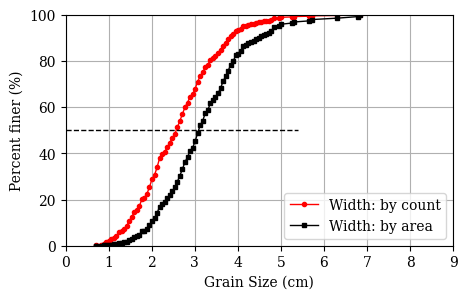

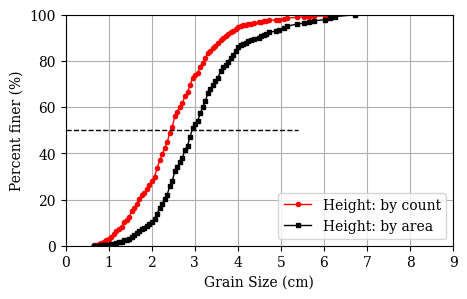

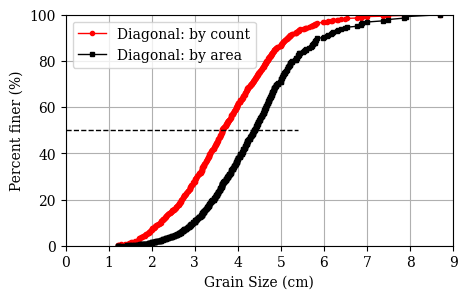

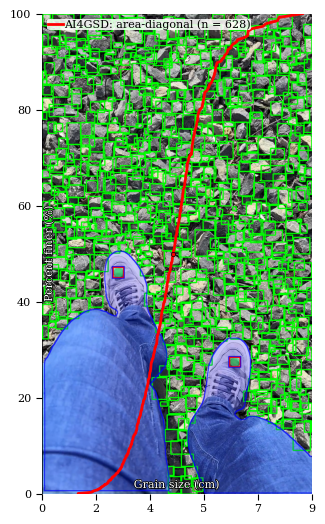

4/4: IMG_9683_2000.png, resolution 0.65 mm/px (100.00%), 12.19 s


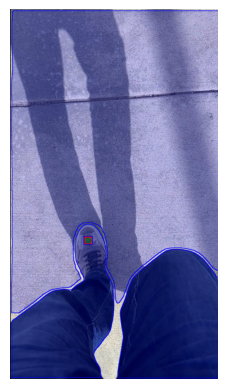

Output folder summary data to: /content/drive/MyDrive/AI4GSD/Demo_Data/20250521_YC_WalkSmartphoneRoadTest/grains_predicts/20250521_YC_WalkSmartphoneRoadTest_YOLO11m.1280.20250322_35/Statistics_V3_20250521_YC_WalkSmartphoneRoadTest_YOLO11m.1280.20250322_35.csv
Total number of grains: 1868, number of grains per photo: 467.00
Total time: 55.79 s, time per photo 13.95 s

Output all summary data to: /content/drive/MyDrive/AI4GSD/Demo_Data/20250521_YC_WalkSmartphoneRoadTest/Statistics_V3_20250521_YC_WalkSmartphoneRoadTest_YOLO11m.1280.20250322_35.csv
Total execution time: 55.99 s


In [10]:
PP = AI4GSD.parameters()
PP.Directory = PhotoDir
PP.ModelName = 'YOLO11m.1280.20250322'
PP.YOLOSave = False
PP.SaveOverlayLabel = True
PP.OverWriteAll = True
PP.PrintOnScreen = True
PP.MaximumGrainSize = 0.15
PP.OverlayFontSize = 4
PP.OverlayLegendFontSize = 4
PP.OverlayGSDTickLineWidth = 4
gsd = AI4GSD.Photo2GSD(PP)

### 7. Applying quality control

In [11]:
gsdqc, stqc = AI4GSD.qualityControl(PhotoDir)


Quality control summary for 20250521_YC_WalkSmartphoneRoadTest:
1/1: IMG_9683.MOV, time 36.2 s, area 3.1 m2, valid area 2.2 m2 (71.8%), frame 4, valid frame 3 (75.0%)
1/1: ***, grain number 1868, number per image 467.0; efficiency 0.1 m2/s, 51.6 grains/s


### 8. Data visualization

#### Metadata and pixel sizes for all images

In [12]:
print(scales.head(10).T.to_string())

                                                                                0                                   1                                   2                                   3
Name                                                             IMG_9683_500.png                   IMG_9683_1000.png                   IMG_9683_1500.png                   IMG_9683_2000.png
Folder                                         20250521_YC_WalkSmartphoneRoadTest  20250521_YC_WalkSmartphoneRoadTest  20250521_YC_WalkSmartphoneRoadTest  20250521_YC_WalkSmartphoneRoadTest
Scale_source                                                             greencap                            greencap                            greencap                            greencap
L1_px1_pixel                                                                486.0                               771.0                               283.0                               386.0
L1_py1_pixel                                      

#### Grain size data before quality control

In [13]:
print(gsd.head(10).T.to_string())

                                                                                                         0                                                            1                                                            2                                                            3
Name                                                                                      IMG_9683_500.png                                            IMG_9683_1000.png                                            IMG_9683_1500.png                                            IMG_9683_2000.png
Folder                                                                  20250521_YC_WalkSmartphoneRoadTest                           20250521_YC_WalkSmartphoneRoadTest                           20250521_YC_WalkSmartphoneRoadTest                           20250521_YC_WalkSmartphoneRoadTest
Save_folder                                    20250521_YC_WalkSmartphoneRoadTest_YOLO11m.1280.20250322_35  20250521_YC_WalkSmartp

#### Grain size data after quality control

In [14]:
print(gsdqc.head(10).T.to_string())

                                                                                                         0                                                            1                                                            2
Name                                                                                      IMG_9683_500.png                                            IMG_9683_1000.png                                            IMG_9683_1500.png
Folder                                                                  20250521_YC_WalkSmartphoneRoadTest                           20250521_YC_WalkSmartphoneRoadTest                           20250521_YC_WalkSmartphoneRoadTest
Save_folder                                    20250521_YC_WalkSmartphoneRoadTest_YOLO11m.1280.20250322_35  20250521_YC_WalkSmartphoneRoadTest_YOLO11m.1280.20250322_35  20250521_YC_WalkSmartphoneRoadTest_YOLO11m.1280.20250322_35
Model_ID                                                                            

#### Summary for each video

In [15]:
print(stqc.head(10).T.to_string())

                                                               0
Folder                        20250521_YC_WalkSmartphoneRoadTest
Data_type                                                    0.0
Video_ID                                                     0.0
Video_name                                                9683.0
Frame_rate_fps                                         59.958573
Width_px                                                  1080.0
Height_px                                                 1920.0
Dimension_megapixel                                       2.0736
Duration_s                                             36.208333
Grain_number_qc0                                          1868.0
Area_qc0_m2                                             3.106951
Area_qc2_m2                                             2.229944
Area_ratio_qc2                                          0.717728
Total_frame                                                  4.0
Frame_qc0                